# P4 (extra): detección de matrículas mediante contornos

Alternativa clásica, sin aprendizaje, al detector YOLO de matrículas entrenado en `VC_P4.ipynb`. Se compara con él sobre el mismo split de **test** y con el mismo evaluador.

Se consideran dos escenarios:

- **Imagen completa**: buscar matrículas en toda la imagen.
- **Dentro de vehículos**: primero se detectan los vehículos con `yolo11n.pt` (coche, moto, autobús, camión) y la matrícula se busca solo dentro de cada uno,
  en su parte inferior. Así funciona el prototipo de la P4 sobre el vídeo.

Los parámetros se ajustaron con el split de **val**. El de test solo se usa para la evaluación final.

In [1]:
import os, glob, time
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

DATA_DIR = os.path.abspath('dataset_matriculas')
BEST_PT  = os.path.abspath('runs/detect/matriculas_yolo11n/weights/best.pt')
IMG_DIR  = 'imagenes'
VEHICULOS = [2, 3, 5, 7]   # COCO: car, motorcycle, bus, truck
os.makedirs(IMG_DIR, exist_ok=True)

## 1. Método

Una matrícula española es un rectángulo claro, con una proporción de unos 4,7:1 (520×110 mm), con caracteres oscuros
que generan muchos **bordes verticales** muy juntos. El método aprovecha esas propiedades:

1. **Black-hat** (cierre − imagen) con un elemento rectangular de 13×5: realza los elementos oscuros y pequeños sobre fondo claro, es decir, los caracteres.
2. **Sobel en x** sobre el black-hat, normalizado y suavizado: mapa de bordes verticales.
3. **Cierre morfológico horizontal** (17×3): une los caracteres de una matrícula en un solo bloque.
4. **Umbral de Otsu** y una erosión/dilatación para limpiar ruido.
5. **Máscara de zonas claras** (Otsu sobre la imagen en grises): el bloque tiene que estar sobre fondo claro.
6. **Contornos externos** (`findContours`) y filtrado de su rectángulo envolvente:
   - tamaño mínimo (25×8 px) y máximo (60 % del ancho y 30 % del alto de la imagen);
   - proporción ancho/alto entre 2 y 7;
   - *relleno* (área del contorno / área del rectángulo) ≥ 0,45, porque una matrícula es compacta.
7. **Puntuación** de cada candidato: densidad de bordes × relleno × cercanía de la proporción a 4,5.
   Sirve para ordenar los candidatos y calcular curvas precisión-recall, igual que la confianza de YOLO.
8. Se repite a varias escalas (1, ½ y ¼) y se fusionan los candidatos con **NMS**.

**Dentro de vehículos:** cada vehículo se recorta con un margen del 5 % y se reescala a 480 px de ancho, para que la matrícula tenga un tamaño
más uniforme. Solo se aceptan candidatos cuyo centro esté en el 65 % inferior del vehículo, y como mucho 2 por vehículo.

In [2]:
def iou(a, b):
    x1, y1 = np.maximum(a[0], b[:, 0]), np.maximum(a[1], b[:, 1])
    x2, y2 = np.minimum(a[2], b[:, 2]), np.minimum(a[3], b[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / ((a[2]-a[0])*(a[3]-a[1]) + (b[:, 2]-b[:, 0])*(b[:, 3]-b[:, 1]) - inter + 1e-9)

def nms(cajas, scores, thr=0.3):
    orden, keep = np.argsort(-scores), []
    while len(orden):
        i = orden[0]; keep.append(i)
        orden = orden[1:][iou(cajas[i], cajas[orden[1:]]) < thr] if len(orden) > 1 else orden[:0]
    return keep

def pasos_contornos(gris):
    # Devuelve los mapas intermedios del método (para una escala)
    bh = cv2.morphologyEx(gris, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5)))
    gx = np.abs(cv2.Sobel(bh, cv2.CV_32F, 1, 0, ksize=3))
    gx = cv2.GaussianBlur((255 * (gx - gx.min()) / (gx.max() - gx.min() + 1e-6)).astype(np.uint8), (5, 5), 0)
    cerr = cv2.morphologyEx(gx, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (17, 3)))
    _, bin_ = cv2.threshold(cerr, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    bin_ = cv2.dilate(cv2.erode(bin_, None, iterations=1), None, iterations=2)
    _, claro = cv2.threshold(cv2.morphologyEx(gris, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8)), 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    mascara = cv2.bitwise_and(bin_, bin_, mask=cv2.dilate(claro, None, iterations=1))
    return dict(blackhat=bh, sobel_x=gx, cierre=cerr, binaria=bin_, claro=claro, final=mascara)

def detecta_contornos(img, escalas=(1.0, 0.5, 0.25), ar=(2.0, 7.0), relleno_min=0.45, max_det=10):
    gris_full = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    cajas, scores = [], []
    for s in escalas:
        gris = gris_full if s == 1 else cv2.resize(gris_full, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        H, W = gris.shape
        p = pasos_contornos(gris)
        cnts, _ = cv2.findContours(p['final'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            x, y, w, h = cv2.boundingRect(c)
            if h < 8 or w < 25 or w > 0.6 * W or h > 0.3 * H or not (ar[0] <= w / h <= ar[1]):
                continue
            relleno = cv2.contourArea(c) / (w * h)
            if relleno < relleno_min:
                continue
            score = p['sobel_x'][y:y+h, x:x+w].mean() / 255 * relleno * np.exp(-((w / h - 4.5) / 2.0) ** 2)
            cajas.append([x / s, y / s, (x + w) / s, (y + h) / s]); scores.append(score)
    if not cajas:
        return np.zeros((0, 4)), np.zeros(0)
    cajas, scores = np.array(cajas), np.array(scores)
    k = nms(cajas, scores)[:max_det]
    return cajas[k], scores[k]

ANCHO_VEH, ZONA_INFERIOR, MAX_POR_VEH = 480, 0.35, 2

def recorte_vehiculo(img, caja, margen=0.05):
    H, W = img.shape[:2]
    x1, y1, x2, y2 = caja; mx, my = margen * (x2 - x1), margen * (y2 - y1)
    x1, y1, x2, y2 = int(max(0, x1 - mx)), int(max(0, y1 - my)), int(min(W, x2 + mx)), int(min(H, y2 + my))
    return img[y1:y2, x1:x2], (x1, y1)

def contornos_en_vehiculos(img, vehs):
    cajas, scores = [], []
    for v in vehs:
        c, (ox, oy) = recorte_vehiculo(img, v)
        if min(c.shape[:2]) < 20:
            continue
        s = ANCHO_VEH / c.shape[1]
        cr = cv2.resize(c, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC if s > 1 else cv2.INTER_AREA)
        cj, sc = detecta_contornos(cr, escalas=(1.0, 0.5))
        ok = (cj[:, 1] + cj[:, 3]) / 2 >= ZONA_INFERIOR * cr.shape[0] if len(cj) else np.zeros(0, bool)
        for b, p in zip(cj[ok][:MAX_POR_VEH], sc[ok][:MAX_POR_VEH]):
            cajas.append([b[0] / s + ox, b[1] / s + oy, b[2] / s + ox, b[3] / s + oy]); scores.append(p)
    return np.array(cajas).reshape(-1, 4), np.array(scores)

def yolo_en_vehiculos(modelo, img, vehs):
    # Igual que el prototipo de la P4: detector de matrículas sobre el recorte de cada vehículo
    recs = [r for r in (recorte_vehiculo(img, v) for v in vehs) if min(r[0].shape[:2]) >= 16]
    cajas, scores = [], []
    if recs:
        for (c, (ox, oy)), rm in zip(recs, modelo([c for c, _ in recs], imgsz=320, conf=0.01, verbose=False)):
            for b, p in zip(rm.boxes.xyxy.numpy()[:MAX_POR_VEH], rm.boxes.conf.numpy()[:MAX_POR_VEH]):
                cajas.append([b[0] + ox, b[1] + oy, b[2] + ox, b[3] + oy]); scores.append(p)
    return np.array(cajas).reshape(-1, 4), np.array(scores)

### Pasos intermedios sobre un ejemplo

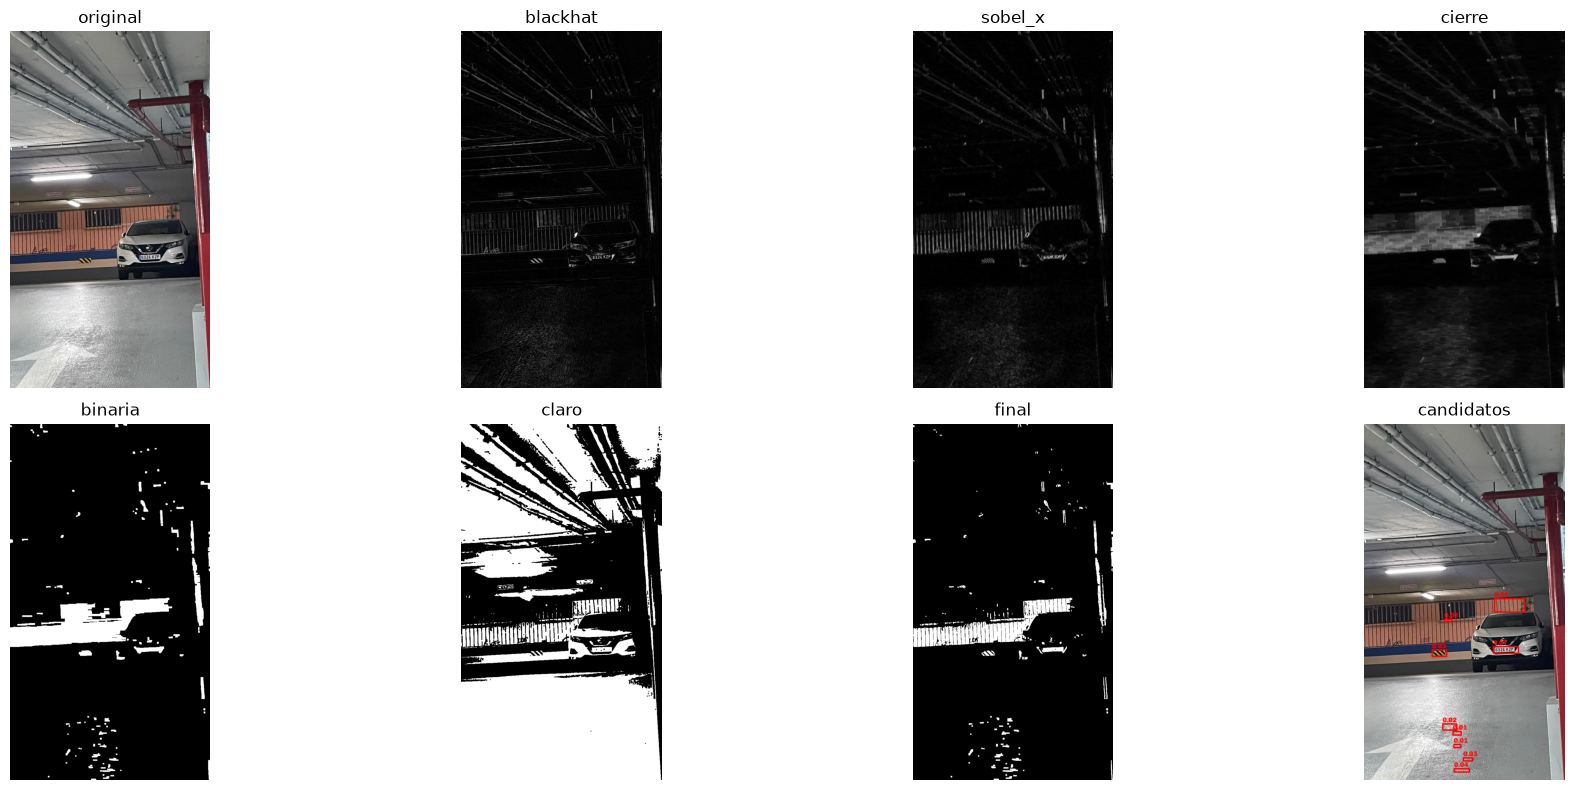

In [3]:
ej = cv2.imread(sorted(glob.glob(os.path.join(DATA_DIR, 'test', 'images', '*.jpg')))[5])
p = pasos_contornos(cv2.cvtColor(ej, cv2.COLOR_BGR2GRAY))
cj, sc = detecta_contornos(ej)
vis = ej.copy()
for (x1, y1, x2, y2), s in zip(cj.astype(int), sc):
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 3)
    cv2.putText(vis, f'{s:.2f}', (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
fig, axs = plt.subplots(2, 4, figsize=(20, 8))
paneles = [('original', ej[:, :, ::-1])] + [(k, v) for k, v in p.items()] + [('candidatos', vis[:, :, ::-1])]
for ax, (t, im) in zip(axs.ravel(), paneles):
    ax.imshow(im, cmap='gray'); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, 'contornos_pasos.jpg'), dpi=70, bbox_inches='tight'); plt.show()

## 2. Evaluación sobre test

**Mismo evaluador para los dos métodos.** Una predicción es correcta si tiene IoU ≥ 0,5 con una matrícula anotada todavía no emparejada
(se recorren en orden de puntuación). A partir de la curva precisión-recall se calculan:

- **AP50**, el área bajo la curva, equivalente al mAP@0.5 de una clase;
- P, R y F1 en el punto de F1 máximo;
- el recall máximo alcanzable.

YOLO se ejecuta con `conf=0.01` para obtener la curva completa.
En el escenario de vehículos, la verdad terreno son las matrículas cuyo centro cae dentro de algún vehículo detectado.

In [4]:
def gt_cajas(ip, W, H):
    lp = ip.replace(os.sep + 'images' + os.sep, os.sep + 'labels' + os.sep).rsplit('.', 1)[0] + '.txt'
    out = [list(map(float, l.split()))[1:] for l in open(lp).read().split('\n') if l.strip()] if os.path.exists(lp) else []
    return np.array([[(xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H] for xc, yc, w, h in out]).reshape(-1, 4)

def gt_en_vehiculos(gt, vehs):
    if not len(gt) or not len(vehs):
        return gt[:0]
    cx, cy = (gt[:, 0] + gt[:, 2]) / 2, (gt[:, 1] + gt[:, 3]) / 2
    dentro = np.zeros(len(gt), bool)
    for x1, y1, x2, y2 in vehs:
        dentro |= (cx >= x1) & (cx <= x2) & (cy >= y1) & (cy <= y2)
    return gt[dentro]

def evalua(items, iou_thr=0.5):
    preds, n_gt, emparejadas = [], 0, []
    for gt, cj, sc in items:
        n_gt += len(gt); usados = np.zeros(len(gt), bool)
        for k in np.argsort(-sc):
            tp = False
            if len(gt):
                io = iou(cj[k], gt); io[usados] = 0; j = io.argmax()
                if io[j] >= iou_thr:
                    usados[j] = tp = True
            preds.append((sc[k], tp))
        emparejadas.append(usados)
    preds.sort(key=lambda p: -p[0])
    tp = np.cumsum([p[1] for p in preds]); fp = np.cumsum([not p[1] for p in preds])
    rec, prec = tp / n_gt, tp / (tp + fp)
    mrec, mpre = np.r_[0, rec, 1], np.r_[1, prec, 0]
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9); b = int(f1.argmax())
    return dict(matriculas=n_gt, AP50=float(np.sum(np.diff(mrec) * mpre[1:])), P=prec[b], R=rec[b], F1=f1[b], R_max=rec[-1]), (rec, prec), emparejadas

modelo_veh, modelo_mat = YOLO('yolo11n.pt'), YOLO(BEST_PT)
ims = sorted(glob.glob(os.path.join(DATA_DIR, 'test', 'images', '*.jpg')))
METODOS = ['Contornos · imagen', 'YOLO · imagen', 'Contornos · vehículos', 'YOLO · vehículos']
items, tiempos = {m: [] for m in METODOS}, {m: 0. for m in METODOS}
t_veh = 0.
for ip in ims:
    img = cv2.imread(ip); H, W = img.shape[:2]; gt = gt_cajas(ip, W, H)
    t0 = time.perf_counter(); vehs = modelo_veh(img, imgsz=640, conf=0.3, classes=VEHICULOS, verbose=False)[0].boxes.xyxy.numpy(); t_veh += time.perf_counter() - t0
    gtv = gt_en_vehiculos(gt, vehs)
    for m, gt_m, f in [('Contornos · imagen', gt, lambda: detecta_contornos(img)),
                       ('YOLO · imagen', gt, lambda: (lambda r: (r.boxes.xyxy.numpy(), r.boxes.conf.numpy()))(modelo_mat(img, imgsz=640, conf=0.01, verbose=False)[0])),
                       ('Contornos · vehículos', gtv, lambda: contornos_en_vehiculos(img, vehs)),
                       ('YOLO · vehículos', gtv, lambda: yolo_en_vehiculos(modelo_mat, img, vehs))]:
        t0 = time.perf_counter(); cj, sc = f(); tiempos[m] += time.perf_counter() - t0
        items[m].append((gt_m, cj, sc))

res, curvas, empar = {}, {}, {}
for m in METODOS:
    res[m], curvas[m], empar[m] = evalua(items[m])
    res[m]['ms_por_imagen'] = 1000 * tiempos[m] / len(ims)
tabla = pd.DataFrame(res).T
print(f'{len(ims)} imágenes de test; detección de vehículos (yolo11n): {1000 * t_veh / len(ims):.0f} ms/imagen, no incluido en la tabla')
display(tabla.style.format({'matriculas': '{:.0f}', 'AP50': '{:.3f}', 'P': '{:.3f}', 'R': '{:.3f}', 'F1': '{:.3f}', 'R_max': '{:.3f}', 'ms_por_imagen': '{:.0f}'}))

477 imágenes de test; detección de vehículos (yolo11n): 25 ms/imagen, no incluido en la tabla


,matriculas,AP50,P,R,F1,R_max,ms_por_imagen
Contornos · imagen,1045,0.135,0.385,0.201,0.264,0.268,9
YOLO · imagen,1045,0.618,0.878,0.614,0.723,0.661,22
Contornos · vehículos,942,0.259,0.503,0.357,0.417,0.412,7
YOLO · vehículos,942,0.590,0.717,0.658,0.686,0.734,26


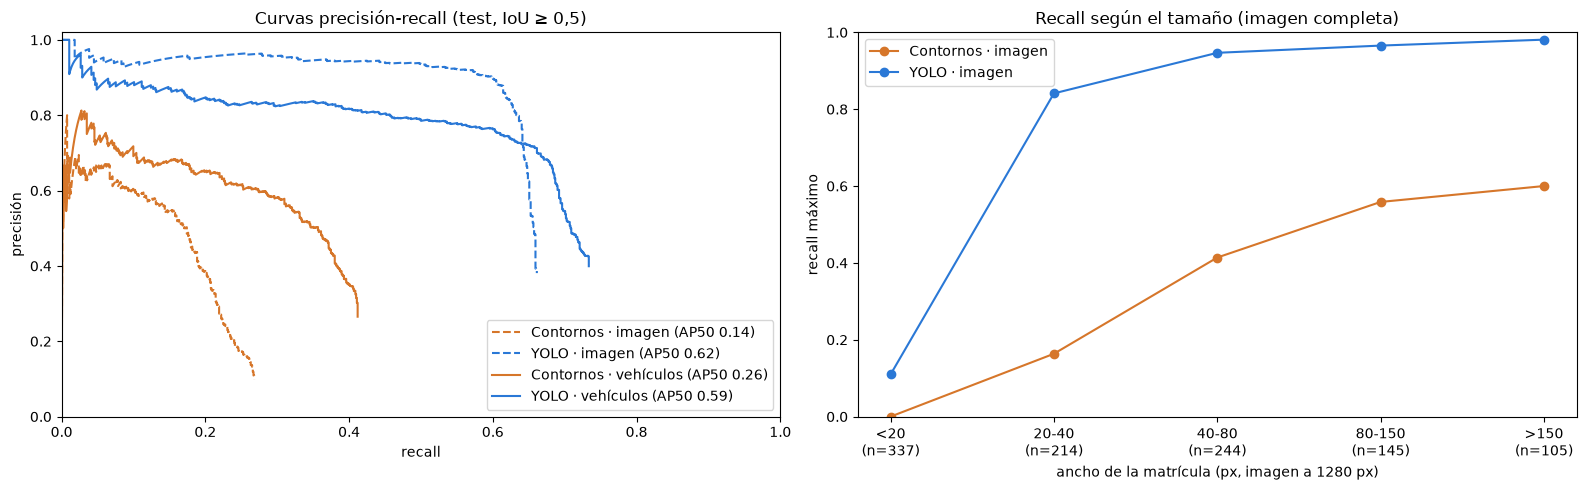

In [5]:
# Curvas precisión-recall y recall según el tamaño de la matrícula
COL = {'Contornos · imagen': '#d6762a', 'YOLO · imagen': '#2a78d6', 'Contornos · vehículos': '#d6762a', 'YOLO · vehículos': '#2a78d6'}
EST = {'Contornos · imagen': '--', 'YOLO · imagen': '--', 'Contornos · vehículos': '-', 'YOLO · vehículos': '-'}
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for m in METODOS:
    rec, prec = curvas[m]
    axs[0].plot(rec, prec, EST[m], color=COL[m], label=f"{m} (AP50 {res[m]['AP50']:.2f})")
axs[0].set_xlabel('recall'); axs[0].set_ylabel('precisión'); axs[0].set_xlim(0, 1); axs[0].set_ylim(0, 1.02)
axs[0].set_title('Curvas precisión-recall (test, IoU ≥ 0,5)'); axs[0].legend()

# recall (en el punto de F1 máximo no; aquí recall máximo) por ancho de la matrícula, escenario imagen completa
bins, etq = [0, 20, 40, 80, 150, 10_000], ['<20', '20-40', '40-80', '80-150', '>150']
for m in ['Contornos · imagen', 'YOLO · imagen']:
    anchos = np.concatenate([g[:, 2] - g[:, 0] for g, _, _ in items[m]])
    ok = np.concatenate(empar[m])
    cat = pd.cut(anchos, bins, labels=etq)
    axs[1].plot(etq, pd.Series(ok).groupby(cat, observed=False).mean().values, 'o-', color=COL[m], label=m)
n_bin = pd.cut(np.concatenate([g[:, 2] - g[:, 0] for g, _, _ in items['YOLO · imagen']]), bins, labels=etq).value_counts().reindex(etq)
axs[1].set_xticks(range(len(etq)), [f'{e}\n(n={n})' for e, n in zip(etq, n_bin)])
axs[1].set_xlabel('ancho de la matrícula (px, imagen a 1280 px)'); axs[1].set_ylabel('recall máximo'); axs[1].set_ylim(0, 1)
axs[1].set_title('Recall según el tamaño (imagen completa)'); axs[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, 'contornos_vs_yolo.png'), dpi=100, bbox_inches='tight'); plt.show()

### Ejemplos

Mismas imágenes de test con los dos métodos en el escenario de vehículos. Verde: matrícula anotada. Rojo: contornos. Azul: YOLO.
Se dibujan las detecciones por encima del umbral de F1 máximo de cada método.

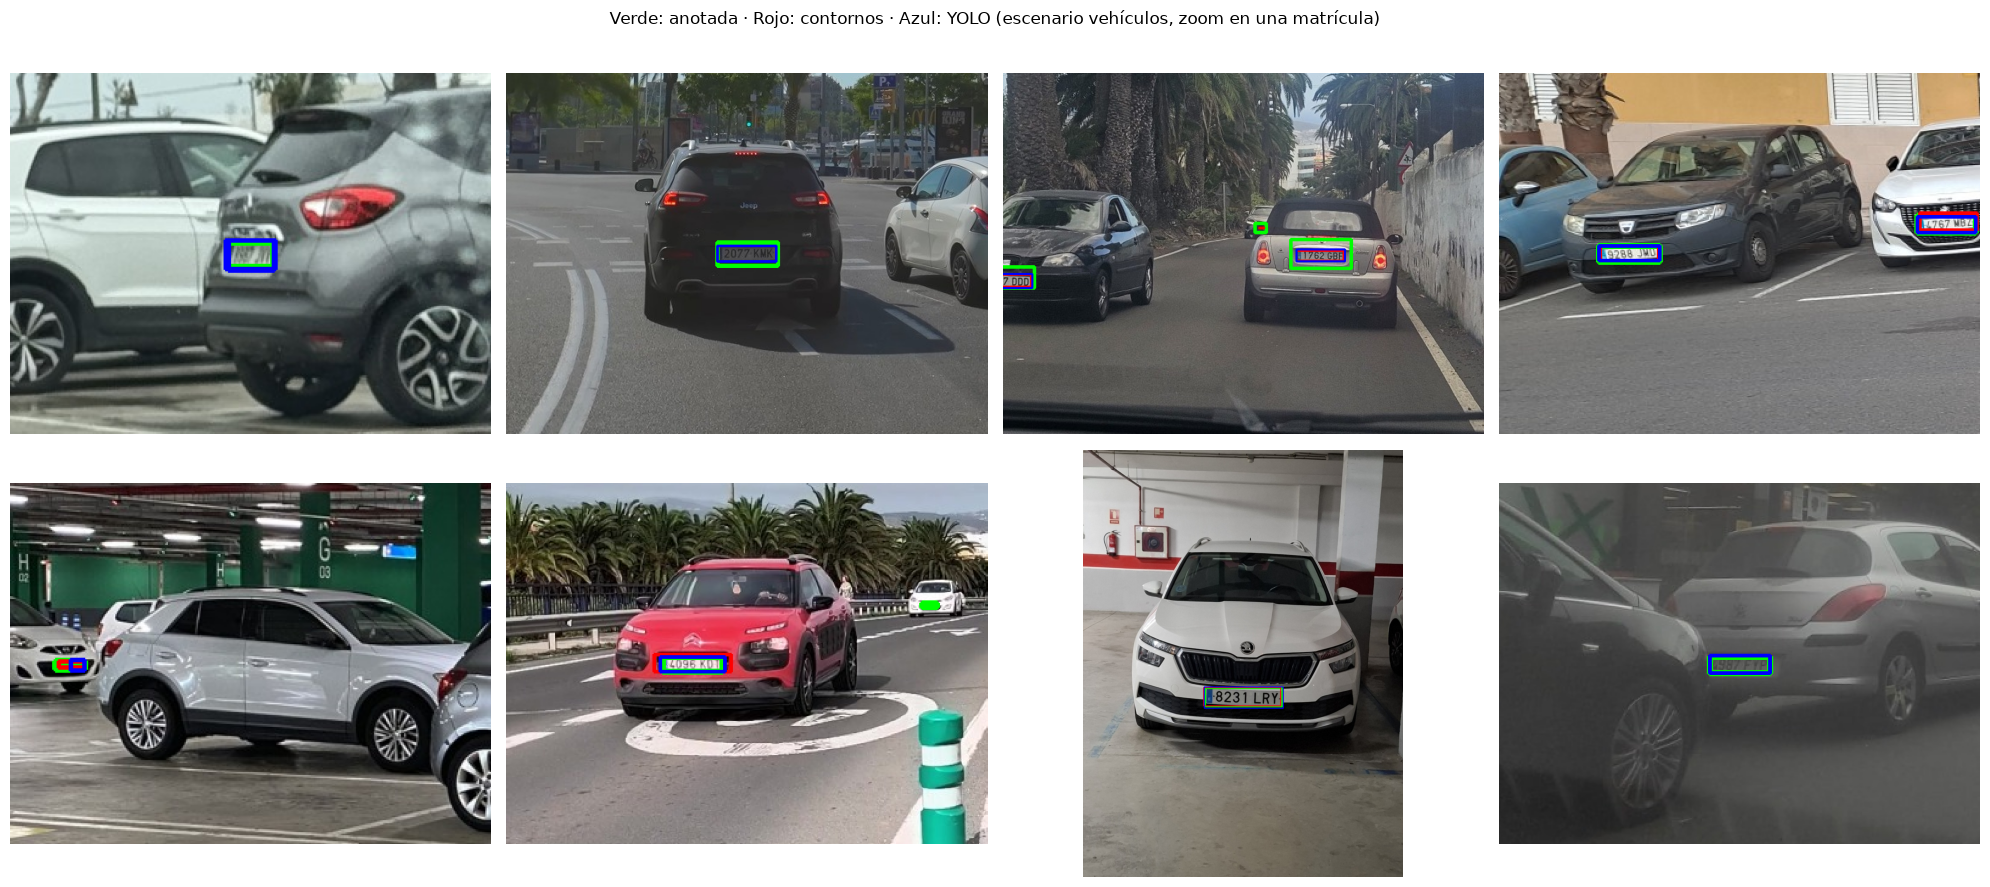

In [6]:
def umbral_f1(m):
    sc = np.sort(np.concatenate([s for _, _, s in items[m]]))[::-1]
    rec, prec = curvas[m]; f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    return sc[int(f1.argmax())]

u = {m: umbral_f1(m) for m in ['Contornos · vehículos', 'YOLO · vehículos']}
idx = [i for i, (g, _, _) in enumerate(items['YOLO · vehículos']) if len(g)]
rng = np.random.default_rng(7); sel = rng.choice(idx, 8, replace=False)
fig, axs = plt.subplots(2, 4, figsize=(20, 9))
for ax, i in zip(axs.ravel(), sel):
    img = cv2.imread(ims[i]); g = items['YOLO · vehículos'][i][0]
    for b in g.astype(int):
        cv2.rectangle(img, tuple(b[:2]), tuple(b[2:]), (0, 255, 0), 4)
    for m, col in [('Contornos · vehículos', (0, 0, 255)), ('YOLO · vehículos', (255, 0, 0))]:
        _, cj, sc = items[m][i]
        for b in cj[sc >= u[m]].astype(int):
            cv2.rectangle(img, tuple(b[:2]), tuple(b[2:]), col, 2)
    # zoom alrededor de la primera matrícula anotada
    x1, y1, x2, y2 = g[0]; cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    w = max(8 * (x2 - x1), 320); h = 0.75 * w
    H, W = img.shape[:2]
    zx1, zy1 = int(np.clip(cx - w / 2, 0, max(0, W - w))), int(np.clip(cy - h / 2, 0, max(0, H - h)))
    ax.imshow(img[zy1:zy1 + int(h), zx1:zx1 + int(w), ::-1]); ax.axis('off')
plt.suptitle('Verde: anotada · Rojo: contornos · Azul: YOLO (escenario vehículos, zoom en una matrícula)')
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, 'contornos_ejemplos.jpg'), dpi=60, bbox_inches='tight'); plt.show()

## 3. Conclusiones

Ver la sección *Extra: detección de matrículas mediante contornos* del [README](README.md).